# Markov HW 4

#### Problem 4 c

In [19]:
import numpy as np
import matplotlib.pyplot as plt


P = np.array([[0,   1/2, 1/2, 0,   0  ], [1/4, 0,   0,   1/2, 1/4], [3/4, 0,   0,   0,   1/4], [0,   0,   0,   1,   0  ], [0,   0,   0,   0,   1  ] ])

names = ["U", "I", "M", "F", "A"]


def inverse_step(probs):

    u = np.random.uniform()
    cumulative = 0

    for num in range(len(probs)):

        cumulative += probs[num]

        if u < cumulative:
            return num


def simulate_one(start):

    state = start
    T = 0

    while state != 3 and state != 4:

        state = inverse_step(P[state])
        T += 1

    return T, state


Nsim = 10000

results = {}

for start in [0, 1, 2]:

    times = np.zeros(Nsim, dtype=int)
    fates = np.zeros(Nsim, dtype=int)

    for r in range(Nsim):
        times[r], fates[r] = simulate_one(start)

    folded = (fates == 3)
    aggregated = (fates == 4)

    h_hat = np.mean(folded)
    g_hat = np.mean(times)

    tau_F_hat = np.mean(times[folded])
    tau_A_hat = np.mean(times[aggregated])

    results[start] = { "times": times, "fates": fates, "h_hat": h_hat, "g_hat": g_hat,  "tau_F_hat": tau_F_hat, "tau_A_hat": tau_A_hat }


h_exact = [1/2, 5/8, 3/8]

g_exact = [4, 2, 4]

tauF_exact = [4, 9/5, 5]

tauA_exact = [4, 7/3, 17/5]



print("Simulation vs Exact Values")
print()

print( "State    h_hat   h_exact    g_hat   g_exact" "    tauF_hat   tauF_exact    tauA_hat   tauA_exact")

for start in [0, 1, 2]:

    r = results[start]

    print( f"{names[start]:<7}" f"{r['h_hat']:<8.4f}" f"{h_exact[start]:<11.4f}" f"{r['g_hat']:<8.4f}" f"{g_exact[start]:<11.4f}" f"{r['tau_F_hat']:<11.4f}"  f"{tauF_exact[start]:<14.4f}" f"{r['tau_A_hat']:<11.4f}"  f"{tauA_exact[start]:.4f}")


Simulation vs Exact Values

State    h_hat   h_exact    g_hat   g_exact    tauF_hat   tauF_exact    tauA_hat   tauA_exact
U      0.5006  0.5000     3.9712  4.0000     4.0028     4.0000        3.9395     4.0000
I      0.6235  0.6250     1.9932  2.0000     1.7997     1.8000        2.3137     2.3333
M      0.3788  0.3750     4.0096  4.0000     4.9873     5.0000        3.4134     3.4000


In [29]:
times_I = results[1]["times"]
fates_I = results[1]["fates"]

T_fold = times_I[fates_I == 3]
T_agg = times_I[fates_I == 4]


Q = P[:3, :3]

R = P[:3, 3:5]


n_vals = np.arange(1, max(times_I) + 1)

pmf_fold = []
pmf_agg = []

for n in n_vals:

    QR = np.linalg.matrix_power(Q, n - 1) @ R


    p_Tn_F = QR[1, 0]
    p_Tn_A = QR[1, 1]


    pmf_fold.append(p_Tn_F / (5/8))
    pmf_agg.append(p_Tn_A / (3/8))

pmf_fold = np.array(pmf_fold)
pmf_agg = np.array(pmf_agg)



bins = np.arange(0.5, max(times_I) + 1.5, 1)


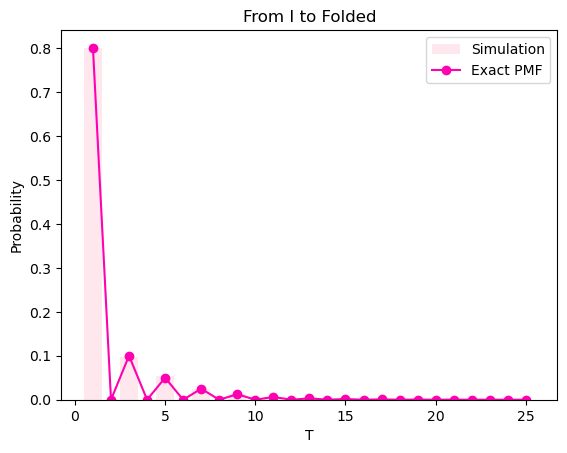

In [45]:
plt.hist( T_fold, bins=bins, density=True, alpha=0.5, label="Simulation", color = "xkcd:light pink")

plt.plot( n_vals, pmf_fold, "o-", label="Exact PMF", color = "xkcd:bright pink")

plt.xlabel("T")
plt.ylabel("Probability")
plt.title("From I to Folded")
plt.legend()

plt.show()

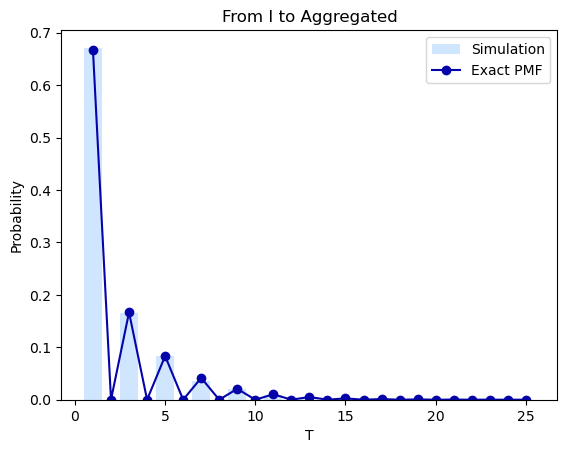

In [39]:

plt.hist( T_agg, bins=bins, density=True, alpha=0.5, label="Simulation", color = "xkcd:baby blue")

plt.plot( n_vals, pmf_agg, "o-", label="Exact PMF", color = "xkcd:royal blue")

plt.xlabel("T")
plt.ylabel("Probability")
plt.title("From I to Aggregated")
plt.legend()

plt.show()